# 06 · Final test

Every earlier result came from cross-validation inside the 280 training rows. The 70 test rows of each dataset were split off in `01_data_preparation` and never used. This notebook uses them **once**, as an independent confirmation of the findings.

## Protocol (fixed before the run; nothing is changed after seeing the results)

1. **Training data**: all 280 training rows of each dataset.
2. **Settings**: the same 10 as the main experiment: clean, missing 10 / 20 / 30 %, noise 0.05 / 0.15 / 0.30 (measured columns only), wrong labels 5 / 10 / 15 %. Damage is applied to the training rows only; the test rows are always clean.
3. **Repetitions**: each setting is run 5 times (r = 0–4). Repetition r sets the damage draw, the inner-fold split and the Random Forest seed, so the result does not rest on one random draw.
4. **Tuning**: every model is tuned on the 280 training rows by stratified 5-fold cross-validation on ROC-AUC, with the same grids as before (quantum: c and C; SVM-RBF: gamma and C; Random Forest; Logistic Regression).
5. **Scoring**: the tuned model is trained on all 280 training rows and scores the 70 test rows. The test score of a setting is the mean over the 5 repetitions.
6. **Uncertainty**: 70 test rows give noisy AUCs, so uncertainty comes from a paired bootstrap over test rows (2,000 resamples). The main claims are tested over all 8 datasets together, as in `04_analysis`.
7. **Claims checked**: (a) quantum vs SVM-RBF on clean data; (b) quantum vs SVM-RBF under damage; (c) wrong labels are the most harmful damage; (d) the test results agree with the cross-validation results.

**Output** (`results/final_test/`): the test-row scores of every model, setting and repetition. Run time about 1–2 hours; a finished dataset is skipped if the cell is run again.

## 0 · Setup

In [1]:
import json, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy import stats
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score

from paths import RESULTS
from quantum_kernel import load_ready, get_states, kernel_from_states
from classical_models import get_model
from corruption import LEVELS, corrupt_training, corruption_seed, noise_columns

DATASETS = ["german_credit", "concrete", "water_potability", "steel_faults",
            "phoneme", "magic_telescope", "bank_marketing", "electricity"]
SHORT = {"german_credit": "German", "concrete": "Concrete", "water_potability": "Water", "steel_faults": "Steel",
         "phoneme": "Phoneme", "magic_telescope": "MAGIC", "bank_marketing": "Bank", "electricity": "Electricity"}
MODELS = {"quantum": "Quantum", "svm_rbf": "SVM-RBF", "random_forest": "RF", "logistic_regression": "LR"}
BANDWIDTHS = [0.01, 0.025, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0]
C_GRID = [0.1, 1, 10]
REPS = [0, 1, 2, 3, 4]
SETTINGS = [("clean", 0.0)] + [(kind, level) for kind, levels in LEVELS.items() for level in levels]
TEST_SEED_OFFSET = 100          # damage seeds differ from the CV runs (seeds 0-4)

OUT, ANALYSIS = RESULTS / "final_test", RESULTS / "analysis"
OUT.mkdir(parents=True, exist_ok=True)


def setting(kind, level):
    if kind == "clean":
        return "clean"
    return f"noise {level:g}" if kind == "noise" else f"{kind} {level:.0%}"


ORDER = [setting(k, l) for k, l in SETTINGS]
print(f"{len(DATASETS)} datasets x {len(SETTINGS)} settings x {len(REPS)} repetitions -> {OUT}")

8 datasets x 10 settings x 5 repetitions -> ./results\final_test


## 1 · One setting, one repetition

The quantum model tunes c and C together by 5-fold cross-validation on precomputed kernels; the classical models use their own grids with the same folds. Each model returns its score for every test row; AUC is computed from these scores.

In [2]:
def quantum_scores(X_tr, y_tr, X_te, q, inner):
    best = (-np.inf, None, None)
    states = {}
    for c in BANDWIDTHS:
        S_tr = get_states(X_tr, q, c=c)
        K = kernel_from_states(S_tr, S_tr)
        states[c] = (S_tr, K)
        for C in C_GRID:
            auc = np.mean([roc_auc_score(y_tr[b], SVC(kernel="precomputed", C=C, class_weight="balanced")
                                         .fit(K[np.ix_(a, a)], y_tr[a]).decision_function(K[np.ix_(b, a)]))
                           for a, b in inner])
            if auc > best[0]:
                best = (auc, c, C)
    _, c, C = best
    S_tr, K = states[c]
    K_te = kernel_from_states(get_states(X_te, q, c=c), S_tr)
    model = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(K, y_tr)
    return model.decision_function(K_te), f"c={c}, C={C}"


def classical_scores(name, X_tr, y_tr, X_te, inner, seed):
    model, grid = get_model(name, seed)
    search = GridSearchCV(model, grid, cv=inner, scoring="roc_auc", n_jobs=-1).fit(X_tr, y_tr)
    s = search.predict_proba(X_te)[:, 1] if name == "random_forest" else search.decision_function(X_te)
    return s, str(search.best_params_)

## 2 · One dataset

In [3]:
def run_dataset(name):
    out = OUT / f"{name}_test.csv"
    if out.exists():
        done = pd.read_csv(out).groupby(["kind", "level", "rep", "model"]).ngroups
        if done == len(SETTINGS) * len(REPS) * len(MODELS):
            print("   already complete - skipped"); return
        out.unlink()
    X_tr0, y_tr0, X_te, y_te = load_ready(name)
    y_tr0, y_te, q, cols = y_tr0.astype(int), y_te.astype(int), X_tr0.shape[1], noise_columns(name)
    rows = []
    for kind, level in SETTINGS:
        for r in REPS:
            if kind == "clean":
                X_tr, y_tr = X_tr0, y_tr0
            else:
                X_tr, y_tr = corrupt_training(X_tr0, y_tr0, kind, level,
                                              corruption_seed(name, kind, TEST_SEED_OFFSET + r, 0), cols)
            inner = list(StratifiedKFold(5, shuffle=True, random_state=r).split(X_tr, y_tr))
            results = {"quantum": quantum_scores(X_tr, y_tr, X_te, q, inner)}
            for m in ["svm_rbf", "random_forest", "logistic_regression"]:
                results[m] = classical_scores(m, X_tr, y_tr, X_te, inner, r)
            for m, (scores, params) in results.items():
                rows += [{"dataset": name, "kind": kind, "level": level, "rep": r, "model": m, "params": params,
                          "row": i, "y": int(y_te[i]), "score": float(s)} for i, s in enumerate(scores)]
    pd.DataFrame(rows).to_csv(out, index=False)
    (OUT / f"{name}_config.json").write_text(json.dumps({
        "dataset": name, "train_rows": int(len(X_tr0)), "test_rows": int(len(X_te)), "qubits": q, "repetitions": REPS,
        "inner_folds": 5, "bandwidths": BANDWIDTHS, "C_grid": C_GRID, "damage_seed_offset": TEST_SEED_OFFSET,
        "versions": {"python": platform.python_version(), "numpy": np.__version__, "scikit-learn": sklearn.__version__}},
        indent=2))

## 3 · Run all eight datasets (the one-time test)

In [4]:
total = time.perf_counter()
for name in DATASETS:
    t = time.perf_counter()
    print(SHORT[name], end=" ")
    run_dataset(name)
    print(f"({time.perf_counter() - t:.0f} s)")
print(f"ALL DONE in {(time.perf_counter() - total) / 60:.1f} min")

German    already complete - skipped
(1 s)
Concrete    already complete - skipped
(0 s)
Water    already complete - skipped
(0 s)
Steel    already complete - skipped
(0 s)
Phoneme    already complete - skipped
(0 s)
MAGIC    already complete - skipped
(0 s)
Bank    already complete - skipped
(0 s)
Electricity    already complete - skipped
(0 s)
ALL DONE in 0.0 min


## 4 · Completeness check

Every dataset: 10 settings × 5 repetitions × 4 models, each with 70 test-row scores.

In [5]:
T = pd.concat([pd.read_csv(OUT / f"{n}_test.csv") for n in DATASETS], ignore_index=True)
T["level"] = T.level.round(4)
T["setting"] = [setting(k, l) for k, l in zip(T.kind, T.level)]
T.groupby("dataset").apply(lambda g: pd.Series({
    "runs": f"{g.groupby(['setting', 'rep', 'model']).ngroups}/200",
    "test rows per run": int(g.groupby(['setting', 'rep', 'model']).size().unique()[0]),
    "missing scores": int(g.score.isna().sum())})).rename(index=SHORT)

,runs,test rows per run,missing scores
dataset,,,
Bank,200/200,70,0
Concrete,200/200,70,0
Electricity,200/200,70,0
German,200/200,70,0
MAGIC,200/200,70,0
Phoneme,200/200,70,0
Steel,200/200,70,0
Water,200/200,70,0


## 5 · Results

### 5.1 Clean data: test AUC next to the cross-validation AUC

Test AUC is the mean over the 5 repetitions; the 95 % interval comes from the bootstrap over the 70 test rows. The cross-validation AUC is the mean of the 25 folds in `03_experiments`.

In [6]:
B = 2000
boot_rng = np.random.default_rng(2026)
BOOT = {}                                   # dataset -> bootstrap row indices, shared by every model (paired)


def boot_idx(name, y):
    if name not in BOOT:
        idx = []
        while len(idx) < B:
            i = boot_rng.integers(0, len(y), len(y))
            if 0 < y[i].sum() < len(y):      # both classes needed for an AUC
                idx.append(i)
        BOOT[name] = np.array(idx)
    return BOOT[name]


def fast_auc(y, S):
    # row-wise ROC-AUC (Mann-Whitney) for label rows y and score rows S, both (k x rows)
    r = stats.rankdata(S, axis=1)
    pos = y.sum(axis=1)
    return ((r * y).sum(axis=1) - pos * (pos + 1) / 2) / (pos * (y.shape[1] - pos))


def auc_table(name, s):
    # (reps x rows) score matrix -> test AUC (mean over reps) and its bootstrap distribution
    g = T[(T.dataset == name) & (T.setting == s)]
    y = g[(g.rep == 0) & (g.model == "quantum")].sort_values("row").y.values
    idx = boot_idx(name, y)
    res = {}
    for m in MODELS:
        S = g[g.model == m].pivot(index="rep", columns="row", values="score").values
        point = np.mean([roc_auc_score(y, srow) for srow in S])
        boot = np.mean([fast_auc(y[idx], srow[idx]) for srow in S], axis=0)
        res[m] = (point, boot)
    return res


RES = {(n, s): auc_table(n, s) for n in DATASETS for s in ORDER}
cv = pd.concat([pd.read_csv(RESULTS / "runs" / f"{n}_folds.csv") for n in DATASETS])
cv = cv[cv.kind == "clean"].replace({"model": {"quantum (c,C tuned)": "quantum"}}).groupby(["dataset", "model"]).auc.mean()

rows = {}
for n in DATASETS:
    r = {}
    for m in MODELS:
        point, boot = RES[n, "clean"][m]
        r[(MODELS[m], "test")] = f"{point:.3f} [{np.percentile(boot, 2.5):.2f}, {np.percentile(boot, 97.5):.2f}]"
        r[(MODELS[m], "CV")] = round(cv[n, m], 3)
    rows[SHORT[n]] = r
CLEAN_TEST = pd.DataFrame(rows).T
CLEAN_TEST.columns = pd.MultiIndex.from_tuples(CLEAN_TEST.columns)
CLEAN_TEST.to_csv(ANALYSIS / "final_test_clean.csv")
CLEAN_TEST

Quantum                    SVM-RBF         \
                           test     CV                test     CV   
German       0.746 [0.62, 0.85]  0.719  0.696 [0.56, 0.82]  0.732   
Concrete     0.917 [0.84, 0.97]  0.925  0.938 [0.87, 0.98]   0.93   
Water        0.504 [0.37, 0.64]  0.535  0.452 [0.33, 0.58]  0.627   
Steel        0.832 [0.72, 0.92]  0.747  0.818 [0.71, 0.91]  0.774   
Phoneme      0.871 [0.78, 0.95]  0.849  0.903 [0.83, 0.97]  0.879   
MAGIC        0.851 [0.74, 0.94]  0.849  0.866 [0.76, 0.95]  0.878   
Bank         0.544 [0.32, 0.77]  0.667  0.640 [0.50, 0.77]  0.649   
Electricity  0.747 [0.62, 0.86]  0.777  0.752 [0.62, 0.86]  0.797   

                             RF                         LR         
                           test     CV                test     CV  
German       0.765 [0.64, 0.87]   0.74  0.683 [0.54, 0.81]  0.736  
Concrete     0.953 [0.90, 0.99]  0.925  0.925 [0.86, 0.97]  0.931  
Water        0.545 [0.40, 0.69]  0.603  0.325 [0.20, 0.47]  0.435  
Steel        0.885 [0.79, 0.96]  0.796  0.785 [0.66, 0.88]  0.753  
Phoneme      0.925 [0.85, 0.98]  0.899  0.839 [0.75, 0.92]   0.84  
MAGIC        0.876 [0.78, 0.95]  0.889  0.810 [0.68, 0.92]  0.821  
Bank         0.663 [0.52, 0.80]  0.768  0.558 [0.34, 0.79]  0.632  
Electricity  0.759 [0.62, 0.87]  0.811  0.782 [0.67, 0.89]  0.805

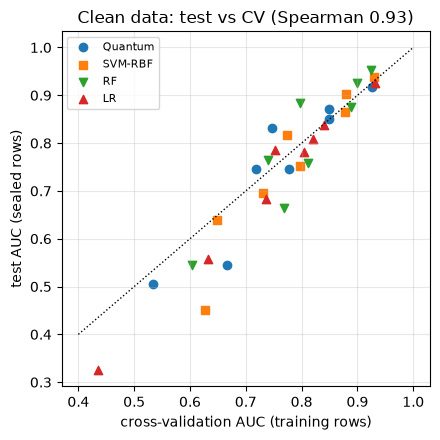

mean test − CV difference: -0.018


In [7]:
pairs = [(cv[n, m], RES[n, "clean"][m][0]) for n in DATASETS for m in MODELS]
cv_vals, test_vals = np.array(pairs).T
rho = stats.spearmanr(cv_vals, test_vals)[0]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for m, mk in zip(MODELS, "osv^"):
    ax.scatter([cv[n, m] for n in DATASETS], [RES[n, "clean"][m][0] for n in DATASETS], marker=mk, label=MODELS[m])
ax.plot([0.4, 1], [0.4, 1], "k:", lw=1)
ax.set_xlabel("cross-validation AUC (training rows)"); ax.set_ylabel("test AUC (sealed rows)")
ax.set_title(f"Clean data: test vs CV (Spearman {rho:.2f})"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(ANALYSIS / "fig_final_test_vs_cv.png", dpi=150); plt.show()
print(f"mean test − CV difference: {np.mean(test_vals - cv_vals):+.3f}")

### 5.2 Quantum minus SVM-RBF on the test rows, all eight datasets together

For each setting: the paired test difference of every dataset, then a random-effects pooled estimate (each dataset weighted by its bootstrap variance) and a Wilcoxon test over the 8 datasets.

In [8]:
def meta(est, var):
    est, var = np.asarray(est), np.asarray(var); k = len(est); w = 1 / var
    fe = (w * est).sum() / w.sum()
    tau2 = max(0.0, ((w * (est - fe) ** 2).sum() - (k - 1)) / (w.sum() - (w ** 2).sum() / w.sum()))
    ws = 1 / (var + tau2); re_ = (ws * est).sum() / ws.sum()
    se = max(np.sqrt((ws * (est - re_) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    return re_, se, 2 * stats.t.sf(abs(re_ / se), k - 1)


rows = []
for s in ORDER:
    est, var, per = [], [], {}
    for n in DATASETS:
        (qp, qb), (rp, rb) = RES[n, s]["quantum"], RES[n, s]["svm_rbf"]
        est.append(qp - rp); var.append((qb - rb).var(ddof=1)); per[SHORT[n]] = round(qp - rp, 3)
    re_, se, p = meta(est, var); t = stats.t.ppf(0.975, 7)
    rows.append({"setting": s, **per, "quantum behind": f"{sum(e < 0 for e in est)}/8", "pooled": round(re_, 3),
                 "95% interval": f"[{re_ - t * se:+.3f}, {re_ + t * se:+.3f}]", "pooled p": round(p, 3),
                 "Wilcoxon p": round(stats.wilcoxon(est).pvalue, 3)})
Q_RBF_TEST = pd.DataFrame(rows).set_index("setting")
Q_RBF_TEST.to_csv(ANALYSIS / "final_test_q_minus_rbf.csv")
Q_RBF_TEST

,German,Concrete,Water,Steel,Phoneme,MAGIC,Bank,Electricity,quantum behind,pooled,95% interval,pooled p,Wilcoxon p
setting,,,,,,,,,,,,,
clean,0.050,-0.022,0.053,0.015,-0.032,-0.015,-0.095,-0.005,5/8,-0.004,"[-0.029, +0.021]",0.730,0.742
missing 10%,0.031,-0.014,-0.006,-0.004,-0.034,-0.027,-0.015,0.003,6/8,-0.013,"[-0.028, +0.003]",0.091,0.195
missing 20%,0.039,0.000,-0.018,-0.046,-0.014,-0.042,-0.072,0.005,5/8,-0.010,"[-0.034, +0.014]",0.350,0.195
missing 30%,0.045,-0.006,-0.018,-0.045,0.002,-0.038,-0.067,-0.020,6/8,-0.014,"[-0.035, +0.007]",0.169,0.195
noise 0.05,0.047,-0.018,0.054,0.014,-0.028,-0.013,-0.089,-0.004,5/8,-0.004,"[-0.027, +0.019]",0.681,0.844
noise 0.15,0.049,-0.020,0.018,0.002,-0.015,-0.061,-0.099,-0.010,5/8,-0.010,"[-0.037, +0.017]",0.415,0.383
noise 0.3,0.052,-0.019,-0.015,-0.004,-0.011,-0.046,-0.085,0.004,6/8,-0.011,"[-0.036, +0.014]",0.343,0.250
labels 5%,0.038,-0.013,-0.003,-0.003,-0.061,-0.056,-0.021,0.002,6/8,-0.016,"[-0.045, +0.013]",0.228,0.148
labels 10%,0.033,-0.008,-0.026,-0.016,-0.050,-0.014,-0.022,-0.010,7/8,-0.009,"[-0.029, +0.010]",0.299,0.148


### 5.3 Which damage hurts most on the test rows?

Change in test AUC from clean at the strongest level of each damage, pooled over the 8 datasets (bootstrap variances, paired with the clean run).

In [9]:
strongest = {kind: setting(kind, levels[-1]) for kind, levels in LEVELS.items()}
rows = {}
for m in MODELS:
    r = {}
    for kind, s in strongest.items():
        est = [RES[n, s][m][0] - RES[n, "clean"][m][0] for n in DATASETS]
        var = [(RES[n, s][m][1] - RES[n, "clean"][m][1]).var(ddof=1) for n in DATASETS]
        re_, se, p = meta(est, var)
        r[s] = f"{re_:+.3f} (p = {p:.2f})"
    rows[MODELS[m]] = r
DROPS_TEST = pd.DataFrame(rows).T
DROPS_TEST.to_csv(ANALYSIS / "final_test_drops.csv")
DROPS_TEST

,missing 30%,noise 0.3,labels 15%
Quantum,-0.033 (p = 0.01),-0.005 (p = 0.33),-0.036 (p = 0.01)
SVM-RBF,-0.024 (p = 0.10),-0.003 (p = 0.32),-0.020 (p = 0.16)
RF,-0.010 (p = 0.16),-0.008 (p = 0.31),-0.029 (p = 0.01)
LR,-0.005 (p = 0.54),+0.001 (p = 0.77),-0.008 (p = 0.58)
